# Sri Lankan Multi-District Weather Forecasting Using Ensemble Learning

This project develops a machine learning-based system to predict next-day maximum temperature, minimum temperature, and rainfall across multiple locations in Sri Lanka using ensemble learning techniques.

## Dataset Description

The dataset contains 65,416 daily weather records from 26 locations in Sri Lanka, covering 2020-01-01 to 2026-11-20. It includes temperature, rainfall, wind speed, humidity, and geographical information.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load dataset
DATA_PATH = Path("../data/raw/sri_lanka_weather_daily.csv")
df = pd.read_csv(DATA_PATH)

print("DATASET LOADED SUCCESSFULLY")
print("=" * 50)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

DATASET LOADED SUCCESSFULLY
Dataset Shape: (65416, 9)

First 5 Records:


,date,city,latitude,longitude,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct
0,2020-01-01,Ampara,7.2975,81.6820,30.0,23.7,3.4,13.7,87
1,2020-01-01,Anuradhapura,8.3114,80.4037,30.1,23.2,1.3,14.1,87
2,2020-01-01,Badulla,6.9934,81.0550,26.7,18.7,1.6,7.2,85
3,2020-01-01,Batticaloa,7.7310,81.6747,29.6,24.6,2.9,18.0,85
4,2020-01-01,Colombo,6.9271,79.8612,29.0,24.2,1.1,11.0,88



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 65416 entries, 0 to 65415
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                65416 non-null  str    
 1   city                65416 non-null  str    
 2   latitude            65416 non-null  float64
 3   longitude           65416 non-null  float64
 4   temp_max_c          65416 non-null  float64
 5   temp_min_c          65416 non-null  float64
 6   precipitation_mm    65416 non-null  float64
 7   wind_speed_max_kmh  65416 non-null  float64
 8   humidity_mean_pct   65416 non-null  int64  
dtypes: float64(6), int64(1), str(2)
memory usage: 5.6 MB


## Data Quality Investigation

The dataset was checked for missing values, duplicates, invalid weather measurements, and data consistency. No missing values, duplicates, or invalid values were identified. Therefore, the dataset passed the implemented data quality checks.

In [3]:

print("DATA QUALITY INVESTIGATION")
print("=" * 50)

print("\n1. Missing Values:")
display(df.isnull().sum())

print("\n2. Total Duplicate Rows:")
print(df.duplicated().sum())

print("\n3. Duplicate Date-City Records:")
print(df.duplicated(subset=["date", "city"]).sum())

print("\n4. Number of Unique Cities:")
print(df["city"].nunique())

print("\n5. Cities:")
print(sorted(df["city"].unique()))

print("\n6. Date Coverage:")
df["date"] = pd.to_datetime(df["date"])
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())
print("Unique Dates:", df["date"].nunique())

print("\n7. Data Types:")
display(df.dtypes)

print("\n8. Numerical Summary:")
display(df.describe())

print("\n9. Weather Data Validity Checks:")

print("Negative Precipitation Values:",
      (df["precipitation_mm"] < 0).sum())

print("Negative Wind Speed Values:",
      (df["wind_speed_max_kmh"] < 0).sum())

print("Invalid Humidity Values:",
      ((df["humidity_mean_pct"] < 0) |
       (df["humidity_mean_pct"] > 100)).sum())

print("Maximum Temperature Below Minimum Temperature:",
      (df["temp_max_c"] < df["temp_min_c"]).sum())

print("\nDATA QUALITY INVESTIGATION COMPLETED")


DATA QUALITY INVESTIGATION

1. Missing Values:


date                  0
city                  0
latitude              0
longitude             0
temp_max_c            0
temp_min_c            0
precipitation_mm      0
wind_speed_max_kmh    0
humidity_mean_pct     0
dtype: int64


2. Total Duplicate Rows:
0

3. Duplicate Date-City Records:
0

4. Number of Unique Cities:
26

5. Cities:
['Ampara', 'Anuradhapura', 'Badulla', 'Batticaloa', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalutara', 'Kandy', 'Kegalle', 'Kilinochchi', 'Kurunegala', 'Mannar', 'Matale', 'Matara', 'Monaragala', 'Mullaitivu', 'Nuwara Eliya', 'Polonnaruwa', 'Puttalam', 'Ratnapura', 'Trincomalee', 'Vavuniya', 'Wellawaya']

6. Date Coverage:
Start Date: 2020-01-01 00:00:00
End Date: 2026-11-20 00:00:00
Unique Dates: 2516

7. Data Types:


date                  datetime64[us]
city                             str
latitude                     float64
longitude                    float64
temp_max_c                   float64
temp_min_c                   float64
precipitation_mm             float64
wind_speed_max_kmh           float64
humidity_mean_pct              int64
dtype: object


8. Numerical Summary:


,date,latitude,longitude,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct
count,65416,65416.000000,65416.000000,65416.000000,65416.000000,65416.000000,65416.000000,65416.000000
mean,2023-06-11 12:00:00,7.554385,80.608458,30.194359,23.438235,5.778042,17.624019,80.338923
min,2020-01-01 00:00:00,5.954900,79.828300,14.700000,5.800000,0.000000,3.300000,41.000000
25%,2021-09-20 18:00:00,6.872800,80.221000,28.700000,22.500000,0.300000,12.700000,75.000000
50%,2023-06-11 12:00:00,7.294050,80.526050,30.200000,23.900000,1.900000,16.700000,81.000000
75%,2025-03-01 06:00:00,8.311400,81.055000,32.100000,25.100000,6.900000,21.400000,87.000000
max,2026-11-20 00:00:00,9.661500,81.682000,40.400000,30.400000,321.800000,76.000000,100.000000
std,NaN,1.027365,0.532904,3.305399,2.918312,10.576739,6.819461,8.341137



9. Weather Data Validity Checks:
Negative Precipitation Values: 0
Negative Wind Speed Values: 0
Invalid Humidity Values: 0
Maximum Temperature Below Minimum Temperature: 0

DATA QUALITY INVESTIGATION COMPLETED


## Further Data Validation

Additional checks were performed to verify daily weather records, city-wise data coverage, and date continuity across all locations.

In [4]:
# Further Data Validation

print("FURTHER DATA VALIDATION")
print("=" * 50)

# 1. Maximum temperature should be >= minimum temperature
print("\n1. Invalid Temperature Records:")
print((df["temp_max_c"] < df["temp_min_c"]).sum())

# 2. Negative rainfall
print("\n2. Negative Rainfall Records:")
print((df["precipitation_mm"] < 0).sum())

# 3. Negative wind speed
print("\n3. Negative Wind Speed Records:")
print((df["wind_speed_max_kmh"] < 0).sum())

# 4. Humidity outside 0-100
print("\n4. Invalid Humidity Records:")
print(((df["humidity_mean_pct"] < 0) |
       (df["humidity_mean_pct"] > 100)).sum())

# 5. Records per city
print("\n5. Records Per City:")
display(df.groupby("city").size().to_frame("record_count"))

# 6. Check date-city coverage
expected_records = df["date"].nunique() * df["city"].nunique()

print("\n6. Expected Records:", expected_records)
print("Actual Records:", len(df))
print("Complete Date-City Coverage:", len(df) == expected_records)

# 7. Check missing calendar dates
all_dates = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing_dates = all_dates.difference(df["date"].unique())

print("\n7. Missing Calendar Dates:", len(missing_dates))

FURTHER DATA VALIDATION

1. Invalid Temperature Records:
0

2. Negative Rainfall Records:
0

3. Negative Wind Speed Records:
0

4. Invalid Humidity Records:
0

5. Records Per City:


,record_count
city,
Ampara,2516
Anuradhapura,2516
Badulla,2516
Batticaloa,2516
Colombo,2516
Galle,2516
Gampaha,2516
Hambantota,2516
Jaffna,2516



6. Expected Records: 65416
Actual Records: 65416
Complete Date-City Coverage: True

7. Missing Calendar Dates: 0


## Preprocessing and Feature Engineering

The dataset was sorted by city and date. Next-day weather targets, calendar features, lag features, and rolling averages were created to capture temporal weather patterns. Rows with missing target or feature values were removed.

In [5]:
# STEP 6: PREPROCESSING & FEATURE ENGINEERING

df = df.sort_values(["city", "date"]).copy()

# Create next-day prediction targets
target_columns = [
    "next_day_temp_max",
    "next_day_temp_min",
    "next_day_rainfall"
]

df[target_columns[0]] = df.groupby("city")["temp_max_c"].shift(-1)
df[target_columns[1]] = df.groupby("city")["temp_min_c"].shift(-1)
df[target_columns[2]] = df.groupby("city")["precipitation_mm"].shift(-1)

# Calendar features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["day_of_year"] = df["date"].dt.dayofyear

# Cyclical date features
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
df["day_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

# Previous weather observations
weather_columns = [
    "temp_max_c",
    "temp_min_c",
    "precipitation_mm",
    "wind_speed_max_kmh",
    "humidity_mean_pct"
]

for col in weather_columns:
    for lag in [1, 2, 3, 7]:
        df[f"{col}_lag_{lag}"] = df.groupby("city")[col].shift(lag)

    df[f"{col}_rolling_3"] = (
        df.groupby("city")[col]
        .transform(lambda s: s.rolling(3).mean())
    )

# Remove rows without targets or lag values
df_model = df.dropna().copy()

print("PREPROCESSING COMPLETED")
print("=" * 50)
print("Original records:", len(df))
print("Records after preprocessing:", len(df_model))
print("Features created:", len(df_model.columns))
print("Missing values:", df_model.isnull().sum().sum())

display(df_model.head())

C:\Users\senur\AppData\Local\Temp\ipykernel_21652\731074736.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek
C:\Users\senur\AppData\Local\Temp\ipykernel_21652\731074736.py:21: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["date"].dt.dayofyear


PREPROCESSING COMPLETED
Original records: 65416
Records after preprocessing: 65208
Features created: 46
Missing values: 0


,date,city,latitude,longitude,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct,next_day_temp_max,...,wind_speed_max_kmh_lag_1,wind_speed_max_kmh_lag_2,wind_speed_max_kmh_lag_3,wind_speed_max_kmh_lag_7,wind_speed_max_kmh_rolling_3,humidity_mean_pct_lag_1,humidity_mean_pct_lag_2,humidity_mean_pct_lag_3,humidity_mean_pct_lag_7,humidity_mean_pct_rolling_3
182,2020-01-08,Ampara,7.2975,81.682,29.3,23.1,2.1,17.6,84,29.4,...,16.1,14.6,13.5,13.7,16.100000,88.0,86.0,84.0,87.0,86.000000
208,2020-01-09,Ampara,7.2975,81.682,29.4,22.2,1.1,13.7,80,29.1,...,17.6,16.1,14.6,12.2,15.800000,84.0,88.0,86.0,89.0,84.000000
234,2020-01-10,Ampara,7.2975,81.682,29.1,22.6,0.0,11.8,76,27.7,...,13.7,17.6,16.1,14.8,14.366667,80.0,84.0,88.0,86.0,80.000000
260,2020-01-11,Ampara,7.2975,81.682,27.7,22.8,3.6,16.9,86,28.6,...,11.8,13.7,17.6,11.8,14.133333,76.0,80.0,84.0,86.0,80.666667
286,2020-01-12,Ampara,7.2975,81.682,28.6,22.9,5.0,22.7,84,28.8,...,16.9,11.8,13.7,13.5,17.133333,86.0,76.0,80.0,84.0,82.000000


## Train, Validation and Test Split

The dataset was divided chronologically into 70% training, 15% validation, and 15% testing sets. This approach preserves the time order of weather observations for forecasting.

In [6]:
# Chronological 70% / 15% / 15% split

unique_dates = np.sort(df_model["date"].unique())

train_end = int(len(unique_dates) * 0.70)
val_end = int(len(unique_dates) * 0.85)

train_dates = unique_dates[:train_end]
val_dates = unique_dates[train_end:val_end]
test_dates = unique_dates[val_end:]

train_df = df_model[df_model["date"].isin(train_dates)].copy()
val_df = df_model[df_model["date"].isin(val_dates)].copy()
test_df = df_model[df_model["date"].isin(test_dates)].copy()

print("DATA SPLITTING COMPLETED")
print("=" * 50)

for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}:")
    print("Rows:", len(data))
    print("Start:", data["date"].min())
    print("End:", data["date"].max())

DATA SPLITTING COMPLETED

Training:
Rows: 45630
Start: 2020-01-08 00:00:00
End: 2024-10-27 00:00:00

Validation:
Rows: 9776
Start: 2024-10-28 00:00:00
End: 2025-11-07 00:00:00

Testing:
Rows: 9802
Start: 2025-11-08 00:00:00
End: 2026-11-19 00:00:00


## Bagging – Random Forest

Random Forest was implemented as the bagging approach. Three configurations were trained and compared using validation MAE, RMSE, and R². The best-performing configuration was selected for further evaluation.

In [7]:
# STEP 8: BAGGING - RANDOM FOREST

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import joblib
import time

# Define prediction targets
target_columns = [
    "next_day_temp_max",
    "next_day_temp_min",
    "next_day_rainfall"
]

# Select input features (exclude targets and date)
drop_columns = target_columns + ["date"]

feature_columns = [
    col for col in train_df.columns
    if col not in drop_columns
]

X_train = train_df[feature_columns]
y_train = train_df[target_columns]

X_val = val_df[feature_columns]
y_val = val_df[target_columns]

# Identify categorical and numerical features
categorical_features = ["city"]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("city", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

# Hyperparameter candidates
rf_candidates = [
    {"n_estimators": 100, "max_depth": 20, "min_samples_leaf": 1},
    {"n_estimators": 100, "max_depth": 30, "min_samples_leaf": 1},
    {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 2}
]

rf_results = []
best_rf_score = float("inf")
best_rf_model = None

for i, params in enumerate(rf_candidates, start=1):

    print(f"Training Random Forest Candidate {i}/3: {params}")

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.time()
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    rf_results.append({
        "Candidate": i,
        "Parameters": str(params),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time (seconds)": round(time.time() - start_time, 2)
    })

    print(f"Validation MAE: {mae:.4f}")

    if mae < best_rf_score:
        best_rf_score = mae
        best_rf_model = model

# Display tuning results
rf_tuning_results = pd.DataFrame(rf_results)

print("\nRANDOM FOREST HYPERPARAMETER COMPARISON")
display(rf_tuning_results)

print("Best Random Forest selected using validation MAE:", best_rf_score)

Training Random Forest Candidate 1/3: {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 1}
Validation MAE: 2.3033
Training Random Forest Candidate 2/3: {'n_estimators': 100, 'max_depth': 30, 'min_samples_leaf': 1}
Validation MAE: 2.3169
Training Random Forest Candidate 3/3: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 2}
Validation MAE: 2.2699

RANDOM FOREST HYPERPARAMETER COMPARISON


,Candidate,Parameters,MAE,RMSE,R2,Training Time (seconds)
0,1,"{'n_estimators': 100, 'max_depth': 20, 'min_sa...",2.303311,5.563598,0.673917,43.25
1,2,"{'n_estimators': 100, 'max_depth': 30, 'min_sa...",2.316897,5.593786,0.672319,32.98
2,3,"{'n_estimators': 100, 'max_depth': None, 'min_...",2.269851,5.509303,0.680001,29.66


Best Random Forest selected using validation MAE: 2.269851208253415


## Boosting – XGBoost, LightGBM and CatBoost

Three boosting algorithms were implemented and evaluated for multi-output weather prediction. XGBoost and LightGBM were trained using MultiOutputRegressor, while CatBoost used its native MultiRMSE objective. Their performance was compared using validation metrics.

In [8]:

# STEP 9: BOOSTING MODELS
# XGBoost vs LightGBM vs CatBoost

from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

import pandas as pd
import numpy as np
import time

# 1. Preprocessing
boost_preprocessor = ColumnTransformer(
    transformers=[
        ("city", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

# 2. Define Boosting Models
boost_models = {
    "XGBoost": XGBRegressor(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=150,
        max_depth=-1,
        num_leaves=31,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ),

    "CatBoost": CatBoostRegressor(
        iterations=150,
        depth=6,
        learning_rate=0.05,
        loss_function="MultiRMSE",
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
}

# 3. Train and Evaluate Models
boost_trained_models = {}
boost_results = []

for name, estimator in boost_models.items():

    print(f"\nTraining {name}...")

    # LightGBM and XGBoost use MultiOutputRegressor
    # CatBoost supports multi-output directly through MultiRMSE
    if name in ["XGBoost", "LightGBM"]:
        final_estimator = MultiOutputRegressor(estimator)
    else:
        final_estimator = estimator

    model = Pipeline([
        ("preprocessor", boost_preprocessor),
        ("model", final_estimator)
    ])

    start_time = time.time()

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    elapsed = round(time.time() - start_time, 2)

    boost_trained_models[name] = model

    boost_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time (seconds)": elapsed
    })

    print(f"{name} completed!")
    print(f"Validation MAE: {mae:.4f}")
    print(f"Validation RMSE: {rmse:.4f}")
    print(f"Validation R2: {r2:.4f}")
    print(f"Training time: {elapsed} seconds")

# 4. Display Comparison
boost_results_df = pd.DataFrame(boost_results)

print("\nBOOSTING MODEL COMPARISON")
display(boost_results_df.sort_values("MAE").reset_index(drop=True))

print("\nBoosting model training completed successfully!")



Training XGBoost...
XGBoost completed!
Validation MAE: 2.1829
Validation RMSE: 5.4845
Validation R2: 0.6903
Training time: 11.75 seconds

Training LightGBM...
LightGBM completed!
Validation MAE: 2.1896
Validation RMSE: 5.5279
Validation R2: 0.6860
Training time: 2.76 seconds

Training CatBoost...
CatBoost completed!
Validation MAE: 2.2006
Validation RMSE: 5.4449
Validation R2: 0.6808
Training time: 4.54 seconds

BOOSTING MODEL COMPARISON


,Model,MAE,RMSE,R2,Training Time (seconds)
0,XGBoost,2.182940,5.484484,0.690268,11.75
1,LightGBM,2.189562,5.527903,0.685966,2.76
2,CatBoost,2.200616,5.444906,0.680823,4.54



Boosting model training completed successfully!


## Stacking Ensemble

A stacking ensemble was developed using Random Forest, XGBoost, and LightGBM as base models. RidgeCV was used as the meta-learner to combine their predictions. The model was evaluated using validation MAE, RMSE, and R².

In [9]:

# STEP 10: STACKING ENSEMBLE MODEL

from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import time
import numpy as np
import pandas as pd

# 1. Transform features
print("Preparing stacking features...")

X_train_stack = boost_preprocessor.fit_transform(X_train)
X_val_stack = boost_preprocessor.transform(X_val)

# 2. Define diverse base models
base_estimators = [
    ("random_forest", RandomForestRegressor(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )),

    ("xgboost", XGBRegressor(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )),

    ("lightgbm", LGBMRegressor(
        n_estimators=100,
        num_leaves=31,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
]

# 3. Define Stacking Regressor
stacking_base = StackingRegressor(
    estimators=base_estimators,
    final_estimator=RidgeCV(
        alphas=[0.1, 1.0, 10.0]
    ),
    cv=3,
    passthrough=False,
    n_jobs=1
)

# 4. Support all three prediction targets
stacking_model = MultiOutputRegressor(
    stacking_base,
    n_jobs=1
)

# 5. Train Stacking Model
print("\nTraining Stacking Ensemble...")

start_time = time.time()

stacking_model.fit(X_train_stack, y_train)

stacking_predictions = stacking_model.predict(X_val_stack)

stacking_time = round(time.time() - start_time, 2)

# 6. Evaluate
stacking_mae = mean_absolute_error(
    y_val, stacking_predictions
)

stacking_rmse = np.sqrt(
    mean_squared_error(y_val, stacking_predictions)
)

stacking_r2 = r2_score(
    y_val, stacking_predictions
)

stacking_results = pd.DataFrame([{
    "Model": "Stacking Ensemble",
    "MAE": stacking_mae,
    "RMSE": stacking_rmse,
    "R2": stacking_r2,
    "Training Time (seconds)": stacking_time
}])

print("\nSTACKING MODEL COMPLETED")
display(stacking_results)

print("Stacking Validation MAE:", round(stacking_mae, 4))


Preparing stacking features...

Training Stacking Ensemble...

STACKING MODEL COMPLETED


,Model,MAE,RMSE,R2,Training Time (seconds)
0,Stacking Ensemble,2.288461,5.581036,0.654065,214.73


Stacking Validation MAE: 2.2885


## Hybrid Ensemble – Random Forest + ARIMA

A hybrid model was developed by combining Random Forest and ARIMA predictions. Different blending weights were evaluated using validation MAE, and the best weights were selected for each prediction target.

In [10]:

# STEP 11: HYBRID ENSEMBLE - RANDOM FOREST + ARIMA

from statsmodels.tsa.arima.model import ARIMA
import warnings
import time

warnings.filterwarnings("ignore")

# 1. Define target mapping
arima_target_mapping = {
    "next_day_temp_max": "temp_max_c",
    "next_day_temp_min": "temp_min_c",
    "next_day_rainfall": "precipitation_mm"
}

# Check required trained model
assert best_rf_model is not None, "Random Forest model is not trained!"
assert "city" in X_val.columns, "City feature is missing!"

# 2. Random Forest validation predictions
print("Generating Random Forest predictions...")

rf_val_predictions = best_rf_model.predict(X_val)

# 3. Prepare historical weather data
print("\nPreparing ARIMA historical data...")

raw_weather = df[
    ["date", "city", "temp_max_c",
     "temp_min_c", "precipitation_mm"]
].copy()

raw_weather = raw_weather.sort_values(["city", "date"])

validation_dates = np.sort(val_df["date"].unique())

arima_val_predictions = np.zeros(
    (len(val_df), len(target_columns))
)

start_time = time.time()

# 4. Generate ARIMA predictions
for target_index, (target_name, raw_column) in enumerate(
    arima_target_mapping.items()
):

    print(f"\nARIMA target: {target_name}")

    for city in sorted(val_df["city"].unique()):

        city_history = raw_weather[
            raw_weather["city"] == city
        ].set_index("date")[raw_column].sort_index()

        first_date = validation_dates[0]

        history = city_history.loc[:first_date].dropna()

        if len(history) < 30:
            raise ValueError(
                f"Insufficient ARIMA history for {city}"
            )

        arima_result = ARIMA(
            history,
            order=(1, 0, 1)
        ).fit()

        for current_date in validation_dates:

            # FIX: Use iloc[0] instead of [0]
            forecast_value = float(
                arima_result.forecast(steps=1).iloc[0]
            )

            row_mask = (
                (val_df["city"].values == city) &
                (val_df["date"].values == current_date)
            )

            arima_val_predictions[
                row_mask, target_index
            ] = forecast_value

            # Append actual observation for rolling forecast
            next_date = current_date + pd.Timedelta(days=1)

            if next_date in city_history.index:

                actual_value = city_history.loc[next_date]

                arima_result = arima_result.append(
                    [actual_value],
                    refit=False
                )

    print(f"Completed ARIMA for {target_name}")

print(
    "\nARIMA validation prediction time:",
    round(time.time() - start_time, 2),
    "seconds"
)

# 5. Select validation-based blending weights
print("\nSelecting Hybrid Blending Weights...")

weight_candidates = [0.25, 0.50, 0.75]

best_hybrid_weights = {}

hybrid_val_predictions = np.zeros_like(
    rf_val_predictions
)

for target_index, target_name in enumerate(target_columns):

    best_weight = None
    best_mae = float("inf")
    best_prediction = None

    for rf_weight in weight_candidates:

        arima_weight = 1 - rf_weight

        combined_prediction = (
            rf_weight * rf_val_predictions[:, target_index] +
            arima_weight * arima_val_predictions[:, target_index]
        )

        mae = mean_absolute_error(
            y_val.iloc[:, target_index],
            combined_prediction
        )

        if mae < best_mae:

            best_mae = mae
            best_weight = rf_weight
            best_prediction = combined_prediction

    best_hybrid_weights[target_name] = best_weight

    hybrid_val_predictions[:, target_index] = best_prediction

    print(
        f"{target_name}: RF weight={best_weight}, "
        f"ARIMA weight={1-best_weight}, "
        f"MAE={best_mae:.4f}"
    )

# 6. Evaluate Hybrid Model
hybrid_mae = mean_absolute_error(
    y_val, hybrid_val_predictions
)

hybrid_rmse = np.sqrt(
    mean_squared_error(y_val, hybrid_val_predictions)
)

hybrid_r2 = r2_score(
    y_val, hybrid_val_predictions
)

hybrid_results = pd.DataFrame([{
    "Model": "Hybrid RF + ARIMA",
    "MAE": hybrid_mae,
    "RMSE": hybrid_rmse,
    "R2": hybrid_r2
}])

print("\nHYBRID MODEL VALIDATION RESULTS")
display(hybrid_results)

print("\nHybrid model completed successfully!")


Generating Random Forest predictions...

Preparing ARIMA historical data...

ARIMA target: next_day_temp_max
Completed ARIMA for next_day_temp_max

ARIMA target: next_day_temp_min
Completed ARIMA for next_day_temp_min

ARIMA target: next_day_rainfall
Completed ARIMA for next_day_rainfall

ARIMA validation prediction time: 1027.3 seconds

Selecting Hybrid Blending Weights...
next_day_temp_max: RF weight=0.5, ARIMA weight=0.5, MAE=0.8571
next_day_temp_min: RF weight=0.25, ARIMA weight=0.75, MAE=0.5424
next_day_rainfall: RF weight=0.25, ARIMA weight=0.75, MAE=5.2020

HYBRID MODEL VALIDATION RESULTS


,Model,MAE,RMSE,R2
0,Hybrid RF + ARIMA,2.200471,5.410047,0.695065



Hybrid model completed successfully!


In [11]:
# Check whether all model validation results are available

required_variables = [
    "rf_tuning_results",
    "boost_results_df",
    "stacking_results",
    "hybrid_results"
]

for var in required_variables:
    if var in globals():
        print(f"✓ {var} is available")
        print(eval(var))
        print("-" * 60)
    else:
        print(f"✗ {var} is NOT available")

✓ rf_tuning_results is available
   Candidate                                         Parameters       MAE  \
0          1  {'n_estimators': 100, 'max_depth': 20, 'min_sa...  2.303311   
1          2  {'n_estimators': 100, 'max_depth': 30, 'min_sa...  2.316897   
2          3  {'n_estimators': 100, 'max_depth': None, 'min_...  2.269851   

       RMSE        R2  Training Time (seconds)  
0  5.563598  0.673917                    43.25  
1  5.593786  0.672319                    32.98  
2  5.509303  0.680001                    29.66  
------------------------------------------------------------
✓ boost_results_df is available
      Model       MAE      RMSE        R2  Training Time (seconds)
0   XGBoost  2.182940  5.484484  0.690268                    11.75
1  LightGBM  2.189562  5.527903  0.685966                     2.76
2  CatBoost  2.200616  5.444906  0.680823                     4.54
------------------------------------------------------------
✓ stacking_results is available
        

## Validation Model Comparison

The validation performance of all ensemble models was combined and compared using MAE, RMSE, and R² metrics. Models were ranked based on their MAE values.

In [12]:
# Combine validation results from all models

rf_best = rf_tuning_results.loc[
    rf_tuning_results["MAE"].idxmin()
]

rf_comparison = pd.DataFrame([{
    "Model": "Random Forest",
    "MAE": rf_best["MAE"],
    "RMSE": rf_best["RMSE"],
    "R2": rf_best["R2"],
    "Training Time (seconds)": rf_best["Training Time (seconds)"]
}])

# Select boosting results
boost_comparison = boost_results_df.copy()

# Select stacking results
stacking_comparison = stacking_results.copy()

# Select hybrid results
hybrid_comparison = hybrid_results.copy()

# Combine all models
validation_comparison = pd.concat(
    [
        rf_comparison,
        boost_comparison,
        stacking_comparison,
        hybrid_comparison
    ],
    ignore_index=True
)

# Sort by MAE
validation_comparison = validation_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

print("VALIDATION MODEL COMPARISON")
display(validation_comparison.round(4))

VALIDATION MODEL COMPARISON


,Model,MAE,RMSE,R2,Training Time (seconds)
0,XGBoost,2.1829,5.4845,0.6903,11.75
1,LightGBM,2.1896,5.5279,0.6860,2.76
2,Hybrid RF + ARIMA,2.2005,5.4100,0.6951,NaN
3,CatBoost,2.2006,5.4449,0.6808,4.54
4,Random Forest,2.2699,5.5093,0.6800,29.66
5,Stacking Ensemble,2.2885,5.5810,0.6541,214.73


## Test Data Preparation

The test dataset was prepared separately for final model evaluation. Input features and actual target values were extracted to evaluate the trained models on unseen data.

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Separate test features and actual target values
X_test = test_df[feature_columns].copy()
y_test = test_df[target_columns].copy()

print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\nTest date range:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTest data preparation completed!")

Test features shape: (9802, 42)
Test target shape: (9802, 3)

Test date range:
2025-11-08 00:00:00 to 2026-11-19 00:00:00

Test data preparation completed!


## Test Predictions

The trained Random Forest, boosting, and stacking models were used to generate predictions for the unseen test dataset.

In [14]:

# Generate predictions from trained models

print("Generating Random Forest predictions...")
rf_test_predictions = best_rf_model.predict(X_test)

print("Generating Boosting predictions...")
boost_test_predictions = {}

# IMPORTANT: Pass raw X_test to pipeline models
for model_name, model in boost_trained_models.items():
    print(f"Predicting with {model_name}...")
    boost_test_predictions[model_name] = model.predict(X_test)

print("Generating transformed test features for Stacking...")
X_test_boost = boost_preprocessor.transform(X_test)

print("Generating Stacking predictions...")
stacking_test_predictions = stacking_model.predict(X_test_boost)

print("\nAll five model predictions completed successfully!")


Generating Random Forest predictions...
Generating Boosting predictions...
Predicting with XGBoost...
Predicting with LightGBM...
Predicting with CatBoost...
Generating transformed test features for Stacking...
Generating Stacking predictions...

All five model predictions completed successfully!


## Final Test Performance Evaluation

All trained models were evaluated using the unseen test dataset. MAE, RMSE, and R² metrics were calculated to compare their final predictive performance.

In [15]:

# Evaluate test predictions

test_predictions = {
    "Random Forest": rf_test_predictions,
    "XGBoost": boost_test_predictions["XGBoost"],
    "LightGBM": boost_test_predictions["LightGBM"],
    "CatBoost": boost_test_predictions["CatBoost"],
    "Stacking Ensemble": stacking_test_predictions
}

test_results = []

for model_name, predictions in test_predictions.items():

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    test_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

test_comparison = pd.DataFrame(test_results)

test_comparison = test_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

print("FINAL TEST PERFORMANCE COMPARISON")

display(test_comparison.round(4))


FINAL TEST PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2
0,XGBoost,2.2180,7.1961,0.6892
1,LightGBM,2.2272,7.2079,0.6880
2,CatBoost,2.2638,7.2263,0.6713
3,Stacking Ensemble,2.3286,7.1928,0.6624
4,Random Forest,2.3367,7.0916,0.6848


## Hybrid RF + ARIMA – Test Evaluation

The Hybrid Random Forest and ARIMA model was evaluated using the unseen test dataset. The blending weights selected during validation were applied to combine both models' predictions.

In [16]:

import time
import warnings
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

# Use the best blending weights selected during validation
hybrid_weights = best_hybrid_weights.copy()

print("Selected Hybrid Model Weights:")
for target, rf_weight in hybrid_weights.items():
    print(
        f"{target}: RF = {rf_weight}, "
        f"ARIMA = {1 - rf_weight}"
    )

arima_target_mapping = {
    "next_day_temp_max": "temp_max_c",
    "next_day_temp_min": "temp_min_c",
    "next_day_rainfall": "precipitation_mm"
}

# Prepare historical weather data
raw_weather = df[
    ["date", "city", "temp_max_c", "temp_min_c", "precipitation_mm"]
].copy()

raw_weather = raw_weather.sort_values(["city", "date"])

test_dates = np.sort(test_df["date"].unique())

arima_test_predictions = np.zeros(
    (len(test_df), len(target_columns))
)

start_time = time.time()

print("Starting Hybrid RF + ARIMA test evaluation...")

for target_index, target in enumerate(target_columns):

    raw_column = arima_target_mapping[target]

    print(f"\nARIMA target: {target}")

    for city in test_df["city"].unique():

        city_history = (
            raw_weather[raw_weather["city"] == city]
            .set_index("date")[raw_column]
            .sort_index()
        )

        first_test_date = test_dates[0]

        history = city_history.loc[:first_test_date].dropna()

        arima_result = ARIMA(
            history,
            order=(1, 0, 1)
        ).fit()

        for current_date in test_dates:

            forecast_value = float(
                arima_result.forecast(steps=1).iloc[0]
            )

            row_mask = (
                (test_df["city"].values == city) &
                (test_df["date"].values == current_date)
            )

            arima_test_predictions[
                row_mask, target_index
            ] = forecast_value

            next_date = current_date + pd.Timedelta(days=1)

            if next_date in city_history.index:

                actual_value = city_history.loc[next_date]

                arima_result = arima_result.append(
                    [actual_value],
                    refit=False
                )

print("\nARIMA test predictions completed!")

# Generate Hybrid predictions using validation-selected weights
hybrid_test_predictions = (
    rf_test_predictions.copy()
)

for target_index, target in enumerate(target_columns):

    rf_weight = hybrid_weights[target]
    arima_weight = 1 - rf_weight

    hybrid_test_predictions[:, target_index] = (
        rf_weight * rf_test_predictions[:, target_index]
        + arima_weight * arima_test_predictions[:, target_index]
    )

# Evaluate Hybrid model
hybrid_test_mae = mean_absolute_error(
    y_test, hybrid_test_predictions
)

hybrid_test_rmse = np.sqrt(
    mean_squared_error(y_test, hybrid_test_predictions)
)

hybrid_test_r2 = r2_score(
    y_test, hybrid_test_predictions
)

hybrid_test_result = pd.DataFrame([{
    "Model": "Hybrid RF + ARIMA",
    "MAE": hybrid_test_mae,
    "RMSE": hybrid_test_rmse,
    "R2": hybrid_test_r2
}])

print("\nHYBRID TEST RESULTS")
display(hybrid_test_result.round(4))

print(
    "\nTotal Hybrid evaluation time:",
    round(time.time() - start_time, 2),
    "seconds"
)


Selected Hybrid Model Weights:
next_day_temp_max: RF = 0.5, ARIMA = 0.5
next_day_temp_min: RF = 0.25, ARIMA = 0.75
next_day_rainfall: RF = 0.25, ARIMA = 0.75
Starting Hybrid RF + ARIMA test evaluation...

ARIMA target: next_day_temp_max

ARIMA target: next_day_temp_min

ARIMA target: next_day_rainfall

ARIMA test predictions completed!

HYBRID TEST RESULTS


,Model,MAE,RMSE,R2
0,Hybrid RF + ARIMA,2.3052,7.0949,0.6927



Total Hybrid evaluation time: 626.67 seconds


## Final Comparison of All Six Models

The test results of all six ensemble models were combined and compared using MAE, RMSE, and R². The best-performing model was identified based on each evaluation metric.

In [17]:

# Combine all six models' final test results

final_test_comparison = pd.concat(
    [
        test_comparison,
        hybrid_test_result
    ],
    ignore_index=True
)

# Sort by MAE
final_test_comparison = final_test_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

print("FINAL TEST PERFORMANCE - ALL SIX MODELS")

display(final_test_comparison.round(4))

# Identify best model according to each metric
print("\nBEST MODEL BY EACH METRIC")

print(
    "Lowest MAE:",
    final_test_comparison.loc[
        final_test_comparison["MAE"].idxmin(), "Model"
    ]
)

print(
    "Lowest RMSE:",
    final_test_comparison.loc[
        final_test_comparison["RMSE"].idxmin(), "Model"
    ]
)

print(
    "Highest R2:",
    final_test_comparison.loc[
        final_test_comparison["R2"].idxmax(), "Model"
    ]
)


FINAL TEST PERFORMANCE - ALL SIX MODELS


,Model,MAE,RMSE,R2
0,XGBoost,2.2180,7.1961,0.6892
1,LightGBM,2.2272,7.2079,0.6880
2,CatBoost,2.2638,7.2263,0.6713
3,Hybrid RF + ARIMA,2.3052,7.0949,0.6927
4,Stacking Ensemble,2.3286,7.1928,0.6624
5,Random Forest,2.3367,7.0916,0.6848



BEST MODEL BY EACH METRIC
Lowest MAE: XGBoost
Lowest RMSE: Random Forest
Highest R2: Hybrid RF + ARIMA


## Final Model Performance Visualization

Bar charts were created to visually compare the six models based on their final test MAE, RMSE, and R² scores. The charts were also saved for use in the project report.

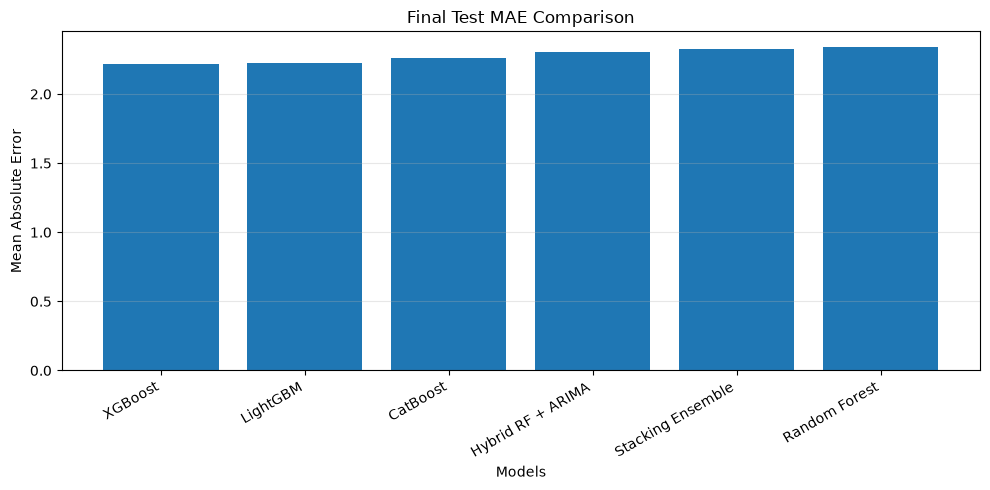

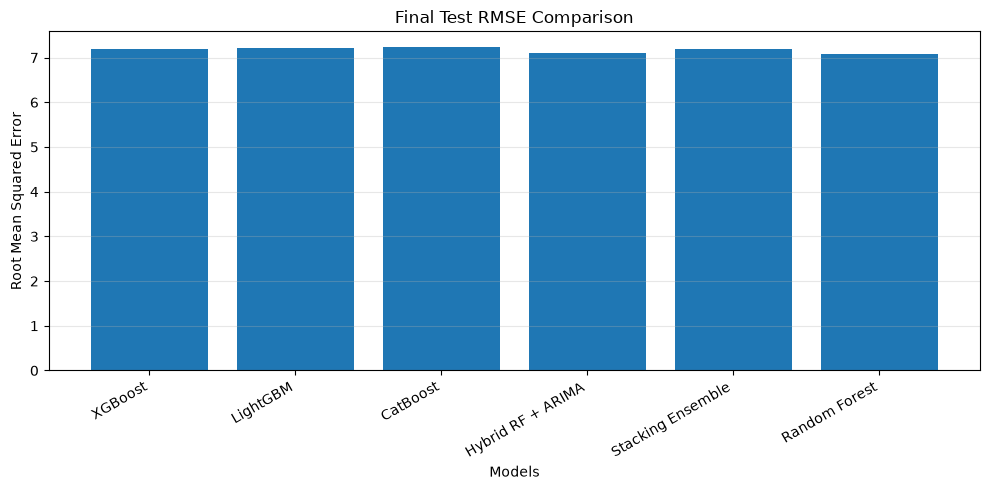

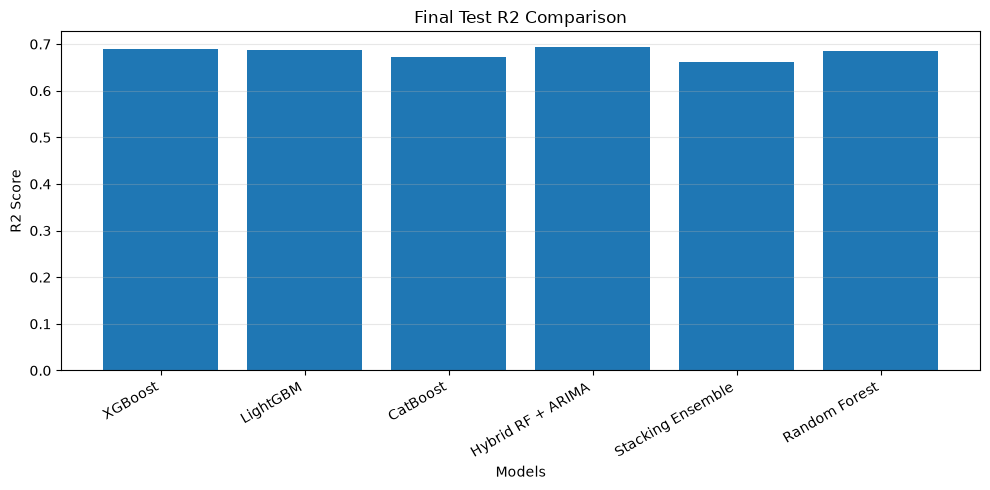

All performance comparison charts saved successfully!


In [18]:

import matplotlib.pyplot as plt
from pathlib import Path

# Create reports folder if it does not exist
REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Prepare results
plot_df = final_test_comparison.copy()

# 1. MAE Comparison
plt.figure(figsize=(10, 5))
plt.bar(plot_df["Model"], plot_df["MAE"])
plt.title("Final Test MAE Comparison")
plt.xlabel("Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "test_mae_comparison.png", dpi=300)
plt.show()

# 2. RMSE Comparison
plt.figure(figsize=(10, 5))
plt.bar(plot_df["Model"], plot_df["RMSE"])
plt.title("Final Test RMSE Comparison")
plt.xlabel("Models")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "test_rmse_comparison.png", dpi=300)
plt.show()

# 3. R2 Comparison
plt.figure(figsize=(10, 5))
plt.bar(plot_df["Model"], plot_df["R2"])
plt.title("Final Test R2 Comparison")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "test_r2_comparison.png", dpi=300)
plt.show()

print("All performance comparison charts saved successfully!")


## Random Forest Feature Importance Analysis

Feature importance scores were extracted from the trained Random Forest model to identify the most influential features in weather prediction. The top 20 features were visualized using a horizontal bar chart.

TOP 20 IMPORTANT FEATURES


,Feature,Importance
0,num__precipitation_mm,0.24985
1,num__temp_max_c_rolling_3,0.10136
2,num__temp_max_c,0.05889
3,num__temp_min_c,0.02707
4,num__wind_speed_max_kmh_lag_7,0.02429
5,num__day_of_year,0.02345
6,num__temp_min_c_rolling_3,0.02326
7,num__day,0.02178
8,num__wind_speed_max_kmh,0.02150
9,num__precipitation_mm_lag_3,0.02149


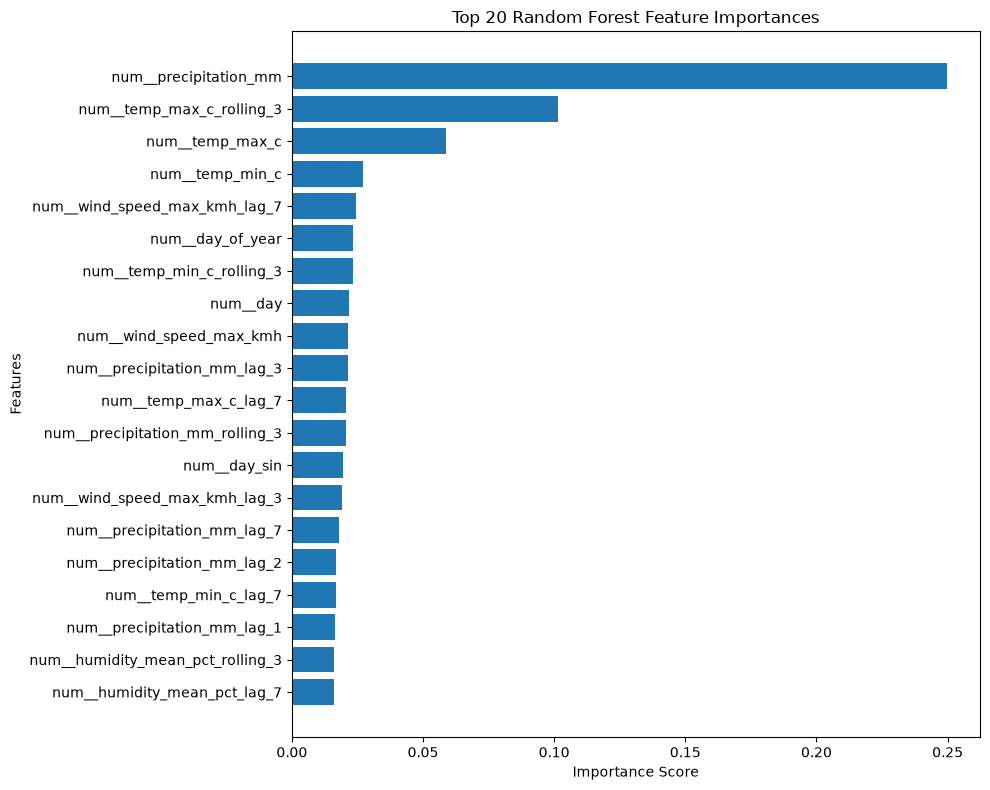

Feature importance chart saved successfully!


In [19]:

# Extract Random Forest feature importance

rf_preprocessor = best_rf_model.named_steps["preprocessor"]
rf_estimator = best_rf_model.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()
feature_importances = rf_estimator.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 20 IMPORTANT FEATURES")
display(feature_importance_df.head(20).round(5))

# Plot top 20 features
top_features = feature_importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "random_forest_feature_importance.png",
    dpi=300
)

plt.show()

print("Feature importance chart saved successfully!")


## Actual vs Predicted Analysis – XGBoost

Actual weather values were compared with XGBoost predictions for the three target variables. The first 300 test records were visualized to examine the model's prediction performance.

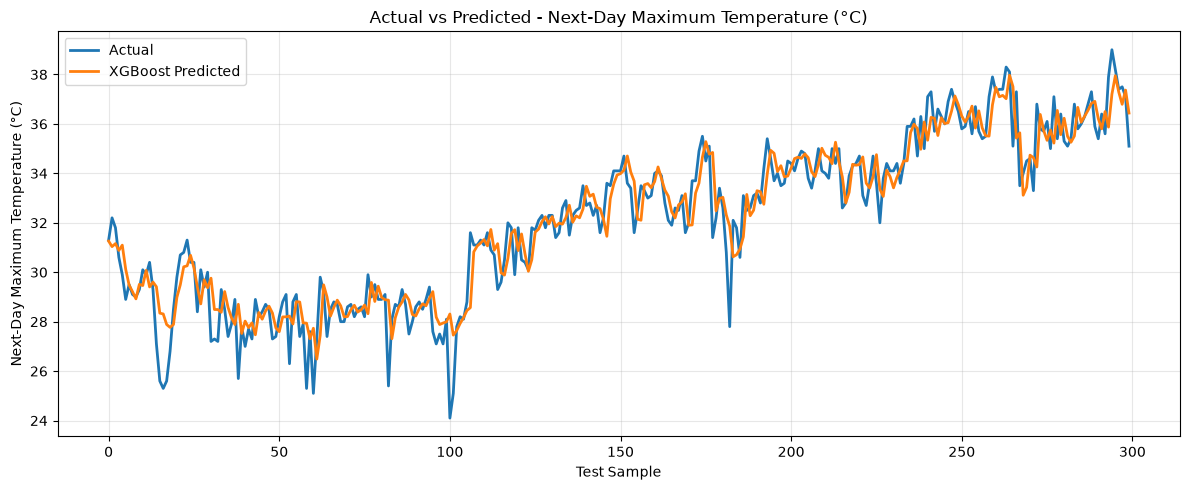

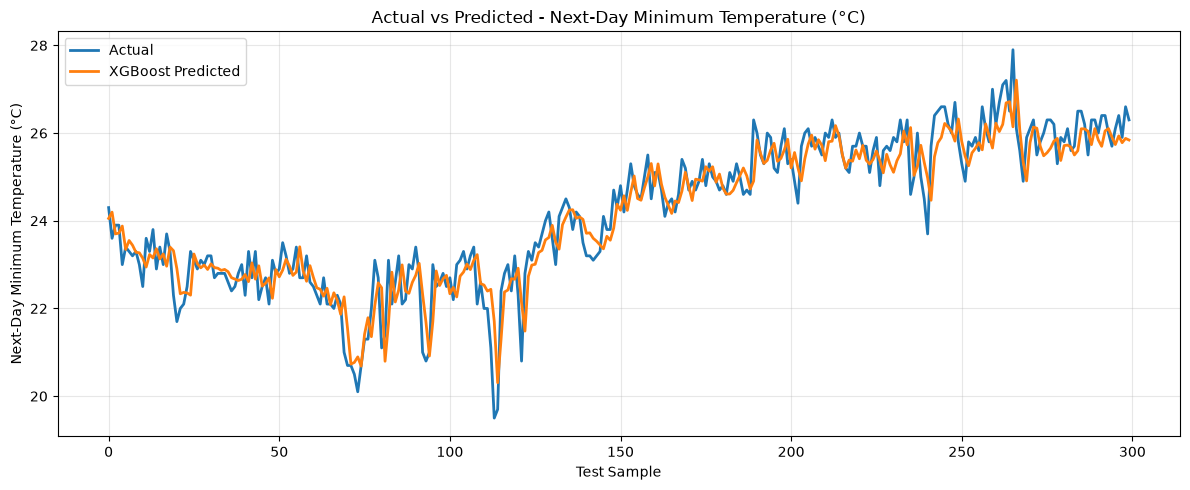

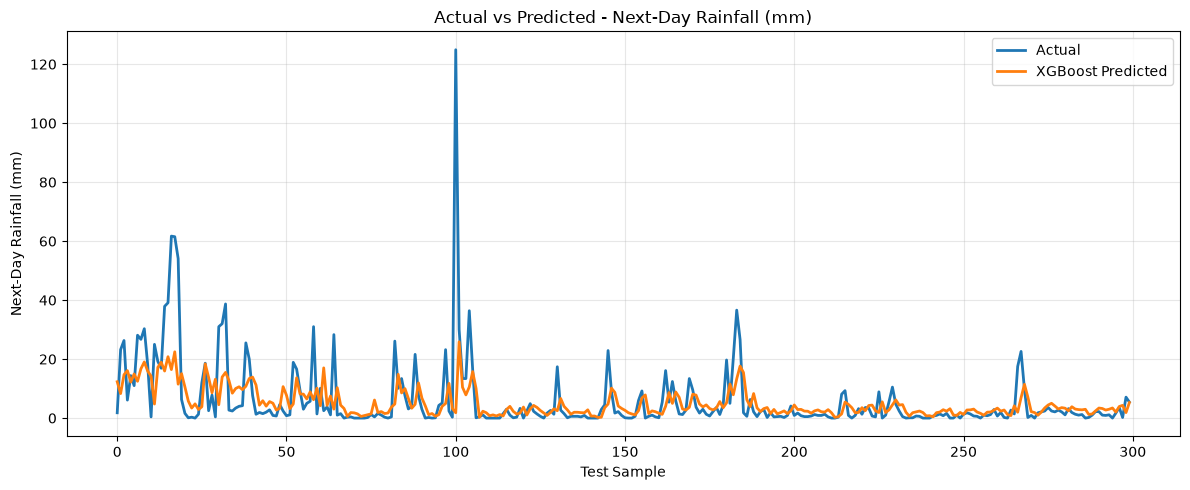

All Actual vs Predicted charts saved successfully!


In [20]:

# Actual vs Predicted plots using XGBoost

target_labels = {
    "next_day_temp_max": "Next-Day Maximum Temperature (°C)",
    "next_day_temp_min": "Next-Day Minimum Temperature (°C)",
    "next_day_rainfall": "Next-Day Rainfall (mm)"
}

# Select a sample of 300 test records
sample_size = min(300, len(y_test))

actual_sample = y_test.iloc[:sample_size]
predicted_sample = boost_test_predictions["XGBoost"][:sample_size]

for i, target in enumerate(target_columns):

    plt.figure(figsize=(12, 5))

    plt.plot(
        range(sample_size),
        actual_sample[target].values,
        label="Actual",
        linewidth=2
    )

    plt.plot(
        range(sample_size),
        predicted_sample[:, i],
        label="XGBoost Predicted",
        linewidth=2
    )

    plt.title(f"Actual vs Predicted - {target_labels[target]}")
    plt.xlabel("Test Sample")
    plt.ylabel(target_labels[target])
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    filename = f"actual_vs_predicted_{target}.png"

    plt.savefig(
        REPORTS_DIR / filename,
        dpi=300
    )

    plt.show()

print("All Actual vs Predicted charts saved successfully!")


## Model Saving and Configuration

All trained ensemble models and project configurations were saved using Joblib. These saved files can be reused for future predictions and dashboard integration without retraining the models.

In [21]:

import joblib
from pathlib import Path

MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save trained models
joblib.dump(best_rf_model, MODELS_DIR / "random_forest.joblib")

joblib.dump(
    boost_trained_models["XGBoost"],
    MODELS_DIR / "xgboost.joblib"
)

joblib.dump(
    boost_trained_models["LightGBM"],
    MODELS_DIR / "lightgbm.joblib"
)

joblib.dump(
    boost_trained_models["CatBoost"],
    MODELS_DIR / "catboost.joblib"
)

# Save stacking model and its fitted preprocessor together
stacking_pipeline = Pipeline([
    ("preprocessor", boost_preprocessor),
    ("model", stacking_model)
])

joblib.dump(
    stacking_pipeline,
    MODELS_DIR / "stacking.joblib"
)

# Save hybrid model configuration
hybrid_config = {
    "rf_model": best_rf_model,
    "weights": hybrid_weights,
    "arima_order": (1, 0, 1),
    "target_mapping": arima_target_mapping
}

joblib.dump(
    hybrid_config,
    MODELS_DIR / "hybrid_rf_arima.joblib"
)

# Save selected project information
project_config = {
    "target_columns": target_columns,
    "feature_columns": feature_columns,
    "preferred_model": "XGBoost",
    "city_list": sorted(df["city"].unique().tolist())
}

joblib.dump(
    project_config,
    MODELS_DIR / "project_config.joblib"
)

print("All models and configurations saved successfully!")

print("\nSaved files:")
for file in MODELS_DIR.iterdir():
    if file.is_file():
        print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")


All models and configurations saved successfully!

Saved files:
catboost.joblib - 0.32 MB
hybrid_rf_arima.joblib - 210.63 MB
lightgbm.joblib - 1.26 MB
project_config.joblib - 0.0 MB
random_forest.joblib - 210.63 MB
stacking.joblib - 265.49 MB
xgboost.joblib - 1.98 MB


## Hybrid Model Configuration Optimization

The Hybrid configuration was saved separately without duplicating the Random Forest model. This reduces storage usage while retaining the blending weights and ARIMA settings required for hybrid predictions.

In [23]:

# Save only Hybrid configuration (without duplicating Random Forest)

hybrid_config = {
    "weights": hybrid_weights,
    "arima_order": (1, 0, 1),
    "target_mapping": arima_target_mapping
}

joblib.dump(
    hybrid_config,
    MODELS_DIR / "hybrid_rf_arima.joblib"
)

print("Hybrid configuration optimized successfully!")
print(
    "New file size:",
    round(
        (MODELS_DIR / "hybrid_rf_arima.joblib").stat().st_size / 1024,
        2
    ),
    "KB"
)


Hybrid configuration optimized successfully!
New file size: 0.21 KB


### AI Tools Usage Acknowledgement

Generative AI tools, including ChatGPT and Google Gemini, were used during the development of this project to assist with debugging code, improving code structure, and developing the Streamlit dashboard interface.

All model development, training, evaluation, result interpretation, and final project decisions were reviewed and verified by the project developer. The developer takes responsibility for the submitted implementation and results.